# Previsão do consumo de energia industrial
## Aplicação de Ciência de Dados na Indústria 4.0

**Avaliação N2 - Ciência de Dados | Inteligência Artificial**  
**Instituição:** Católica de Santa Catarina  
**Professor:** Claudinei Dias (Ney)  
**Integrantes:** André Schultz; José Henrique Brühmüller; Lucas Monich Nunes; Matheus Büsemayer.  
**Data da elaboração:** 27/10/2026.

**Pergunta de pesquisa:** quanto uma siderúrgica consumirá de energia no próximo intervalo de 15 minutos, considerando o histórico de consumo e o calendário?

Este notebook contém texto acadêmico, código executável, gráficos e resultados calculados. Os dados são públicos e históricos; o estudo não envolve instalação em uma fábrica ou economia financeira comprovada.

## 1. Introdução

A Indústria 4.0 integra aquisição de dados, conectividade e sistemas analíticos para apoiar decisões de produção. Nesse contexto, registros de medidores podem transformar o acompanhamento do consumo energético em informação para planejamento operacional. O NIST descreve a manufatura inteligente como a transformação de dados de processos em conhecimento para decisão [1].

### 1.1 Problema

Uma fábrica precisa compatibilizar a operação de equipamentos com a energia disponível. Oscilações de consumo dificultam antecipar períodos de maior utilização. O problema abordado é estimar o consumo de um intervalo futuro curto a partir das medições já encerradas, apoiando a equipe responsável pela operação.

O estudo utiliza medições da DAEWOO Steel Co. Ltd, em Gwangyang, Coreia do Sul, disponibilizadas no repositório UCI [2]. A aplicação ao contexto da Indústria 4.0 está no uso de registros digitais e aprendizado de máquina para apoiar o monitoramento energético. Nenhuma decisão automática sobre máquinas é implementada.

### 1.2 Objetivos

**Objetivo geral:** desenvolver e avaliar uma previsão de consumo de energia elétrica, em kWh por intervalo de 15 minutos.

**Objetivos específicos:**
1. Coletar e auditar dados industriais públicos, registrando sua origem.
2. Descrever o comportamento do consumo por horário e dia da semana.
3. Construir variáveis históricas e um modelo tabular adequado à previsão.
4. Comparar métodos simples com dois algoritmos de regressão.
5. Avaliar erros em um período posterior e discutir possibilidades e limites de uso industrial.

## 2. Metodologia

O fluxo adotado é: entendimento do problema → coleta → auditoria → organização temporal → exploração do treino → modelagem → seleção na validação → avaliação final → discussão.

### 2.1 Fonte, tipos e volume dos dados

O conjunto **Steel Industry Energy Consumption**, de Sathishkumar V E, Changsun Shin e Yongyun Cho, contém 35.040 registros [2], disponibilizados sob licença **CC BY 4.0**. O arquivo original tem campos numéricos e categóricos e uma coluna de data. A contagem de campos será conferida no arquivo, pois a ficha do repositório distingue atributos e outros papéis de variáveis.

A coleta deste trabalho consiste no download de uma fonte secundária pública, não em coleta própria com sensores. Os dados do arquivo serão preservados e seu hash SHA-256 será verificado. As datas são interpretadas como horário local do conjunto original, sem conversão para o fuso brasileiro.

### 2.2 Ambiente

Bibliotecas: pandas e NumPy para preparação; Matplotlib para gráficos; scikit-learn para regressão, pré-processamento e métricas [3]; joblib para salvar o modelo.

**No Google Colab:** envie este arquivo `.ipynb` e execute todas as células. O CSV será baixado automaticamente da UCI se não estiver em `data/raw`. Não é necessário montar o Google Drive. Os arquivos serão gravados em `resultados/`; baixe-os antes de encerrar a sessão.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
PASTA = Path.cwd()
DADOS = PASTA / 'data' / 'raw' / 'Steel_industry_data.csv'
SAIDA = PASTA / 'resultados'
SAIDA.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

versoes = {p: importlib.metadata.version(p)
           for p in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'joblib']}
versoes['python'] = platform.python_version()
display(pd.Series(versoes, name='Versão utilizada').to_frame())

,Versão utilizada
numpy,2.5.4
pandas,3.1.0
matplotlib,3.11.2
scikit-learn,1.9.1
joblib,1.6.0
python,3.13.5


In [2]:
URL = 'https://archive.ics.uci.edu/static/public/851/steel%2Bindustry%2Benergy%2Bconsumption.zip'
HASH_ESPERADO = '9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0fae3c643e82072eacc'
if not DADOS.exists():
    with urlopen(URL, timeout=60) as resposta:
        pacote = resposta.read()
    with ZipFile(BytesIO(pacote)) as arquivo_zip:
        nome = next(n for n in arquivo_zip.namelist()
                    if n.endswith('Steel_industry_data.csv'))
        conteudo = arquivo_zip.read(nome)
    DADOS.parent.mkdir(parents=True, exist_ok=True)
    DADOS.write_bytes(conteudo)

hash_obtido = hashlib.sha256(DADOS.read_bytes()).hexdigest()
assert hash_obtido == HASH_ESPERADO, 'O arquivo mudou; conferir a fonte antes da análise.'
dados = pd.read_csv(DADOS, encoding='utf-8-sig')
print(f'Arquivo original: {dados.shape[0]:,} linhas e {dados.shape[1]} colunas')
display(dados.head())

Arquivo original: 35,040 linhas e 11 colunas


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


### 2.3 Modelo dos dados e dicionário

**Unidade observacional:** uma medição de consumo associada a um intervalo de 15 minutos. A chave temporal é `date`. O alvo do projeto é `Usage_kWh`, mesmo que o repositório atribua outro papel a esse campo em sua ficha. O projeto redefine explicitamente a tarefa como regressão do consumo futuro.

| Campo original | Significado e uso no projeto |
|---|---|
| `date` | Referência temporal, convertida para datetime e usada como chave. |
| `Usage_kWh` | Consumo registrado em kWh; alvo e origem das defasagens. |
| `Lagging_Current_Reactive.Power_kVarh` | Energia reativa indutiva; excluída como preditor contemporâneo. |
| `Leading_Current_Reactive_Power_kVarh` | Energia reativa capacitiva; excluída como preditor contemporâneo. |
| `CO2(tCO2)` | Campo de emissões; excluído. A unidade descrita na ficha é inconsistente com o nome, e não é reinterpretada aqui. |
| `Lagging_Current_Power_Factor` | Fator de potência indutivo; excluído como preditor contemporâneo. |
| `Leading_Current_Power_Factor` | Fator de potência capacitivo; excluído como preditor contemporâneo. |
| `NSM` | Segundos desde a meia-noite; substituídos por calendário derivado de `date`. |
| `WeekStatus` | Indicador de dia útil/fim de semana; recalculado pelo calendário. |
| `Day_of_week` | Dia da semana; recalculado pelo calendário. |
| `Load_Type` | Categoria de carga; excluída porque sua disponibilidade antecipada não é demonstrada. |

**Modelo lógico:** `medicao(date, consumo_kwh, demais_campos)` → `exemplo_previsao(date, historico_ate_t_menos_1, calendario_t, consumo_alvo_t)` → `previsao(date, consumo_observado, consumo_previsto, erro)`.

Não é necessário criar um banco de dados para este volume. CSV e DataFrames representam esse modelo com uma chave temporal verificável. Dados brutos, atributos derivados e resultados ficam separados.

In [3]:
colunas_esperadas = {
    'date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
    'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor',
    'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type'
}
assert set(dados.columns) == colunas_esperadas, 'Esquema diferente do esperado.'
assert len(dados) == 35040
auditoria = {'linhas': len(dados), 'colunas': len(dados.columns),
            'valores_ausentes': int(dados.isna().sum().sum()),
            'linhas_duplicadas': int(dados.duplicated().sum())}
assert auditoria['valores_ausentes'] == 0
assert auditoria['linhas_duplicadas'] == 0
datas_originais = pd.to_datetime(dados['date'], format='%d/%m/%Y %H:%M', errors='raise')
meia_noite = datas_originais.dt.hour.eq(0) & datas_originais.dt.minute.eq(0)
# Na fonte, cada bloco vai de 00:15 a 00:00: esta última leitura encerra o dia.
assert np.flatnonzero(meia_noite).tolist() == list(range(95, len(dados), 96))
dados['date'] = datas_originais + pd.to_timedelta(meia_noite.astype(int), unit='D')
assert not dados['date'].duplicated().any(), 'Datas repetidas exigem investigação.'
# Preservar a ordem original evita deslocar a última medição para o começo do dia.
dados = dados.set_index('date')
assert dados.index.is_monotonic_increasing
assert dados.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=15)).all()
assert pd.api.types.is_numeric_dtype(dados['Usage_kWh'])
assert np.isfinite(dados['Usage_kWh']).all() and dados['Usage_kWh'].ge(0).all()
auditoria.update({'inicio': str(dados.index.min()), 'fim': str(dados.index.max()),
                 'meias_noites_normalizadas': int(meia_noite.sum()),
                 'convencao_temporal': 'fim_intervalo_meia_noite_mais_um_dia',
                 'frequencia_minutos': 15, 'sha256': hash_obtido})
display(pd.Series(auditoria, name='Auditoria').to_frame())

,Auditoria
linhas,35040
colunas,11
valores_ausentes,0
linhas_duplicadas,0
inicio,2018-01-01 00:15:00
fim,2019-01-01 00:00:00
meias_noites_normalizadas,365
convencao_temporal,fim_intervalo_meia_noite_mais_um_dia
frequencia_minutos,15
sha256,9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0...


### 2.4 Preparação e prevenção de vazamento de informação

Dados inválidos não são preenchidos silenciosamente: o notebook interrompe se houver ausências, datas duplicadas, consumo negativo ou lacunas na frequência. Picos não são removidos por serem altos, pois podem representar operação industrial real.

**Normalização da meia-noite:** na ordem original, cada dia contém `00:15`, `00:30`, ..., `23:45`, seguido de `00:00` ainda com a data do mesmo dia. Ordenar literalmente essas datas moveria a última medição diária para o início do dia. Adotamos a convenção de encerramento de intervalo e acrescentamos um dia somente a essas 365 meias-noites, preservando a sequência de aquisição do arquivo. A ordem normalizada deve ser estritamente crescente e ter diferença de 15 minutos em todos os registros; o código verifica isso antes de construir qualquer defasagem. Essa convenção é uma hipótese sustentada pela organização do arquivo, não uma confirmação obtida com a indústria. Os campos de dia da semana e horário são recalculados a partir da data normalizada; o CSV original permanece inalterado.

Para prever o valor `y(t)`, utilizamos `y(t-1)`, `y(t-4)`, `y(t-96)` e `y(t-672)`: respectivamente, consumo de 15 minutos, uma hora, um dia e uma semana antes. As médias das últimas quatro e 96 medições são calculadas após `shift(1)`. Assim, nenhuma média inclui o alvo atual. Hora e dia da semana são transformados em seno e cosseno para representar sua natureza cíclica.

As primeiras 672 linhas não têm histórico semanal completo e são excluídas apenas da tabela de modelagem. Não há imputação do alvo ou geração de medições fictícias.

**Protocolo:** 70% dos exemplos em ordem temporal para treino, 15% para validação e o restante para teste. Não se usa embaralhamento. A validação define o método vencedor pelo menor MAE. O conjunto de teste fica reservado para a avaliação final. O ajuste de escala ocorre dentro de um pipeline treinado apenas com os dados de desenvolvimento correspondentes [4].

**Modo de uso avaliado:** previsão sequencial de um passo. Antes de cada novo intervalo, o consumo dos intervalos anteriores já foi observado. Isso permite usar defasagens que pertencem a intervalos anteriores dentro da validação ou do teste. Não equivale a prever todos os intervalos de um dia sem receber novas medições.

In [4]:
def criar_atributos(serie):
    atributos = pd.DataFrame(index=serie.index)
    for atraso in [1, 4, 96, 672]:
        atributos[f'lag_{atraso}'] = serie.shift(atraso)
    passado = serie.shift(1)
    atributos['media_1h'] = passado.rolling(4).mean()
    atributos['media_24h'] = passado.rolling(96).mean()
    fracao_dia = (serie.index.hour * 60 + serie.index.minute) / (24 * 60)
    atributos['hora_sen'] = np.sin(2 * np.pi * fracao_dia)
    atributos['hora_cos'] = np.cos(2 * np.pi * fracao_dia)
    atributos['semana_sen'] = np.sin(2 * np.pi * serie.index.day_of_week / 7)
    atributos['semana_cos'] = np.cos(2 * np.pi * serie.index.day_of_week / 7)
    atributos['fim_semana'] = (serie.index.day_of_week >= 5).astype(int)
    return atributos

serie = dados['Usage_kWh']
atributos = criar_atributos(serie)
base = atributos.join(serie.rename('alvo_kwh')).dropna()
limite_treino = int(len(base) * 0.70)
limite_validacao = int(len(base) * 0.85)
treino = base.iloc[:limite_treino].copy()
validacao = base.iloc[limite_treino:limite_validacao].copy()
teste = base.iloc[limite_validacao:].copy()
FEATURES = atributos.columns.tolist()

assert len(base) == len(dados) - 672
assert treino.index.max() < validacao.index.min() < teste.index.min()
assert validacao.index.max() < teste.index.min()
assert not set(FEATURES).intersection(colunas_esperadas)
assert base['lag_1'].equals(serie.shift(1).loc[base.index].rename('lag_1'))

# Verificação causal: mudar o alvo em t e todos os valores futuros não muda X(t).
posicao = 1000
instante = serie.index[posicao]
alterada = serie.copy()
alterada.iloc[posicao:] = alterada.iloc[posicao:] + 10000
pd.testing.assert_series_equal(criar_atributos(serie).loc[instante],
                               criar_atributos(alterada).loc[instante])

particoes = pd.DataFrame([
    {'Conjunto': nome, 'Exemplos': len(parte), 'Início': parte.index.min(),
     'Fim': parte.index.max()}
    for nome, parte in [('Treino', treino), ('Validação', validacao), ('Teste', teste)]
])
display(particoes)
print(f'Histórico inicial descartado da modelagem: {len(dados) - len(base)} linhas')

,Conjunto,Exemplos,Início,Fim
0,Treino,24057,2018-01-08 00:15:00,2018-09-15 14:15:00
1,Validação,5155,2018-09-15 14:30:00,2018-11-08 07:00:00
2,Teste,5156,2018-11-08 07:15:00,2019-01-01 00:00:00


Histórico inicial descartado da modelagem: 672 linhas


### 2.5 Métodos de análise e avaliação

A exploração usa somente o período de treino: estatística descritiva, agregações por horário e dia da semana e visualização da série. Essas associações não demonstram causalidade.

São comparados quatro métodos previamente definidos:

| Método | Funcionamento | Papel |
|---|---|---|
| Persistência | Repete o último consumo observado. | Referência simples que explora continuidade. |
| Sazonal diário | Repete o consumo do mesmo horário do dia anterior. | Referência que explora repetição diária. |
| Ridge | Regressão linear com regularização L2, `alpha=1`. | Modelo linear com escala padronizada. |
| HistGradientBoosting | Conjunto de árvores, 150 iterações, taxa 0,08, 15 folhas. | Modelo de relações não lineares. |

Os parâmetros são fixados antecipadamente; não é feita busca extensa. O `early_stopping` do modelo de árvores é desativado para evitar uma divisão interna aleatória. Predições negativas dos modelos aprendidos são limitadas a zero, pois consumo negativo não faz parte deste problema.

**MAE** é a média de `|observado - previsto|`, em kWh, e define a seleção. **RMSE** é a raiz da média dos erros quadráticos e dá mais peso a erros grandes. **R²** compara o erro quadrático com a variabilidade do alvo e pode ser negativo. Não utilizamos MAPE, que pode ficar instável quando o consumo se aproxima de zero. As fórmulas são implementadas pelas métricas oficiais do scikit-learn [5].

## 3. Desenvolvimento
### 3.1 Análise exploratória

Os totais diários mostrados nos extremos do período de treino podem corresponder a dias parciais, porque os cortes são feitos por número de intervalos. Os perfis horário e semanal usam a média por intervalo.

,Consumo por intervalo (kWh)
count,24057.000000
mean,28.718602
std,34.137097
min,2.480000
25%,3.170000
50%,4.750000
75%,52.630000
max,153.140000


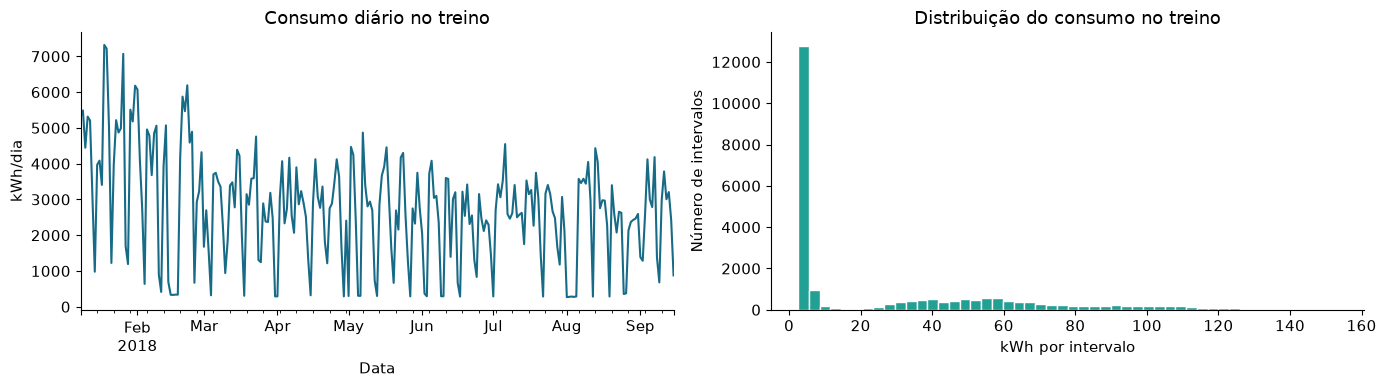

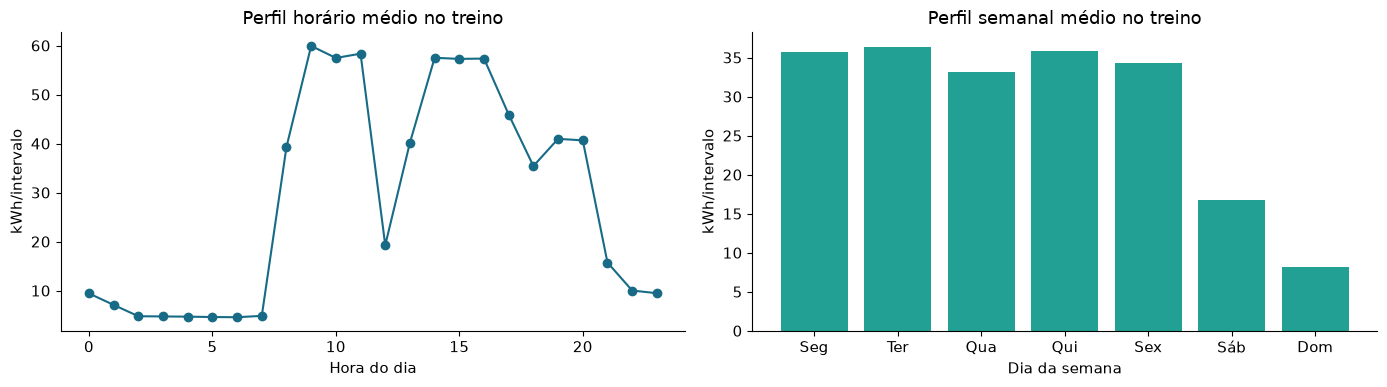

In [5]:
display(treino['alvo_kwh'].describe().to_frame('Consumo por intervalo (kWh)'))
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
treino['alvo_kwh'].resample('D').sum().plot(ax=eixos[0], color='#176b87')
eixos[0].set(title='Consumo diário no treino', xlabel='Data', ylabel='kWh/dia')
treino['alvo_kwh'].plot.hist(bins=50, ax=eixos[1], color='#23a094', edgecolor='white')
eixos[1].set(title='Distribuição do consumo no treino', xlabel='kWh por intervalo',
             ylabel='Número de intervalos')
fig.tight_layout()
fig.savefig(SAIDA / '01_serie_distribuicao.png', dpi=160, bbox_inches='tight')
plt.show()

perfil = treino.assign(hora=treino.index.hour, dia=treino.index.day_of_week)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
perfil.groupby('hora')['alvo_kwh'].mean().plot(ax=eixos[0], marker='o', color='#176b87')
eixos[0].set(title='Perfil horário médio no treino', xlabel='Hora do dia', ylabel='kWh/intervalo')
dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
por_dia = perfil.groupby('dia')['alvo_kwh'].mean().reindex(range(7))
eixos[1].bar(dias, por_dia.values, color='#23a094')
eixos[1].set(title='Perfil semanal médio no treino', xlabel='Dia da semana', ylabel='kWh/intervalo')
fig.tight_layout()
fig.savefig(SAIDA / '02_perfis_calendario.png', dpi=160, bbox_inches='tight')
plt.show()

In [6]:
hora_pico = int(perfil.groupby('hora')['alvo_kwh'].mean().idxmax())
dia_maior = dias[int(por_dia.idxmax())]
media_uteis = perfil.loc[perfil.index.day_of_week < 5, 'alvo_kwh'].mean()
media_fim_semana = perfil.loc[perfil.index.day_of_week >= 5, 'alvo_kwh'].mean()
display(Markdown(
    f'No período de treino, a maior média horária ocorre às **{hora_pico:02d}h**, '
    f'e a maior média por dia da semana ocorre em **{dia_maior}**. '
    f'A média por intervalo é **{media_uteis:.2f} kWh** em dias úteis e '
    f'**{media_fim_semana:.2f} kWh** nos fins de semana. '
    'Esses padrões justificam testar variáveis de calendário, mas não identificam '
    'quais equipamentos causam as diferenças.'
))

No período de treino, a maior média horária ocorre às **09h**, e a maior média por dia da semana ocorre em **Ter**. A média por intervalo é **35.09 kWh** em dias úteis e **12.49 kWh** nos fins de semana. Esses padrões justificam testar variáveis de calendário, mas não identificam quais equipamentos causam as diferenças.

### 3.2 Treinamento e seleção na validação

As referências são avaliadas exatamente nos mesmos instantes que os modelos aprendidos. Não se assume que uma técnica mais complexa será superior. A validação usa um único bloco posterior ao treino; portanto, não representa múltiplos anos nem diferentes fábricas. A pequena diferença entre dois modelos não deve ser tratada como evidência de superioridade estatística.

In [7]:
modelos = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'HistGradientBoosting': HistGradientBoostingRegressor(
        learning_rate=0.08, max_iter=150, max_leaf_nodes=15,
        l2_regularization=1.0, early_stopping=False, random_state=SEED)
}

def calcular_metricas(real, previsto):
    return {'MAE_kWh': mean_absolute_error(real, previsto),
            'RMSE_kWh': np.sqrt(mean_squared_error(real, previsto)),
            'R2': r2_score(real, previsto)}

previsoes_validacao = {
    'Persistência': validacao['lag_1'].to_numpy(),
    'Sazonal diário': validacao['lag_96'].to_numpy()
}
for nome, modelo in modelos.items():
    modelo.fit(treino[FEATURES], treino['alvo_kwh'])
    previsoes_validacao[nome] = np.maximum(0, modelo.predict(validacao[FEATURES]))

metricas_validacao = pd.DataFrame({
    nome: calcular_metricas(validacao['alvo_kwh'], previsao)
    for nome, previsao in previsoes_validacao.items()
}).T.sort_values('MAE_kWh')
metricas_validacao.index.name = 'Método'
vencedor = metricas_validacao.index[0]
display(metricas_validacao.round(4))
print(f'Método escolhido exclusivamente na validação: {vencedor}')

,MAE_kWh,RMSE_kWh,R2
Método,,,
HistGradientBoosting,4.3028,8.9778,0.9143
Persistência,5.6976,12.6292,0.8303
Ridge,6.6490,11.7714,0.8526
Sazonal diário,15.2170,28.8099,0.1170


Método escolhido exclusivamente na validação: HistGradientBoosting


### 3.3 Avaliação final no teste

Após a escolha, o modelo vencedor é reajustado com treino e validação juntos, sem usar os alvos do teste no ajuste. Se uma referência simples vencer, ela é mantida como método final. São mostrados o método selecionado e as duas referências; não há nova escolha de método com base nos resultados do teste.

In [8]:
desenvolvimento = pd.concat([treino, validacao])
previsoes_teste = {
    'Persistência': teste['lag_1'].to_numpy(),
    'Sazonal diário': teste['lag_96'].to_numpy()
}
modelo_final = None
if vencedor in modelos:
    modelo_final = clone(modelos[vencedor])
    modelo_final.fit(desenvolvimento[FEATURES], desenvolvimento['alvo_kwh'])
    previsoes_teste[vencedor] = np.maximum(0, modelo_final.predict(teste[FEATURES]))

metricas_teste = pd.DataFrame({
    nome: calcular_metricas(teste['alvo_kwh'], previsto)
    for nome, previsto in previsoes_teste.items()
}).T
metricas_teste.index.name = 'Método'
display(metricas_teste.round(4))
previsao_final = previsoes_teste[vencedor]
assert len(previsao_final) == len(teste) and np.isfinite(previsao_final).all()

,MAE_kWh,RMSE_kWh,R2
Método,,,
Persistência,4.9954,11.6387,0.8615
Sazonal diário,14.6174,26.9966,0.2547
HistGradientBoosting,3.8957,7.9050,0.9361


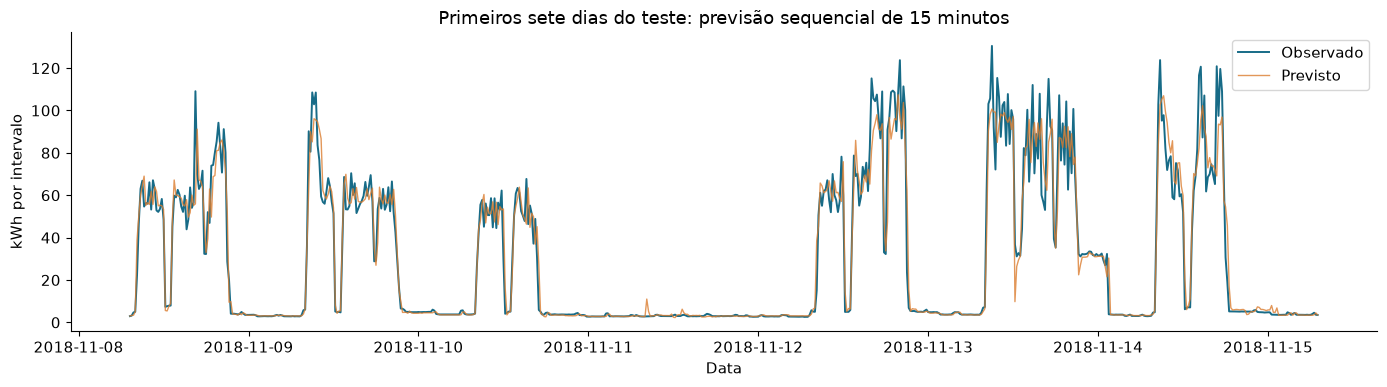

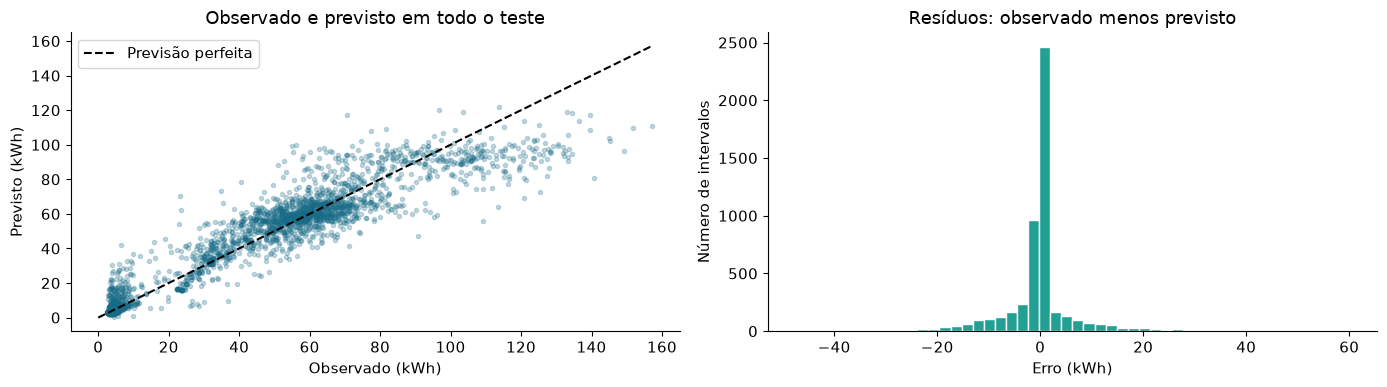

In [9]:
resultado = pd.DataFrame({
    'observado_kwh': teste['alvo_kwh'], 'previsto_kwh': previsao_final,
    'persistencia_kwh': previsoes_teste['Persistência'],
    'sazonal_diario_kwh': previsoes_teste['Sazonal diário']
}, index=teste.index)
resultado['erro_kwh'] = resultado['observado_kwh'] - resultado['previsto_kwh']
resultado['erro_absoluto_kwh'] = resultado['erro_kwh'].abs()

fig, ax = plt.subplots(figsize=(14, 4))
recorte = resultado.iloc[:96 * 7]
ax.plot(recorte.index, recorte['observado_kwh'], label='Observado', color='#176b87', linewidth=1.4)
ax.plot(recorte.index, recorte['previsto_kwh'], label='Previsto', color='#db7d30', linewidth=1.0, alpha=0.8)
ax.set(title='Primeiros sete dias do teste: previsão sequencial de 15 minutos',
       xlabel='Data', ylabel='kWh por intervalo')
ax.legend()
fig.tight_layout()
fig.savefig(SAIDA / '03_observado_previsto.png', dpi=160, bbox_inches='tight')
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
eixos[0].scatter(resultado['observado_kwh'], resultado['previsto_kwh'], s=9, alpha=0.25, color='#176b87')
maximo = resultado[['observado_kwh', 'previsto_kwh']].to_numpy().max()
eixos[0].plot([0, maximo], [0, maximo], '--', color='black', label='Previsão perfeita')
eixos[0].set(title='Observado e previsto em todo o teste', xlabel='Observado (kWh)', ylabel='Previsto (kWh)')
eixos[0].legend()
resultado['erro_kwh'].plot.hist(bins=50, ax=eixos[1], color='#23a094', edgecolor='white')
eixos[1].set(title='Resíduos: observado menos previsto', xlabel='Erro (kWh)', ylabel='Número de intervalos')
fig.tight_layout()
fig.savefig(SAIDA / '04_diagnostico_erros.png', dpi=160, bbox_inches='tight')
plt.show()

### 3.4 Comportamento em períodos de consumo elevado

Um erro médio baixo pode esconder dificuldades nos maiores consumos. Definimos **consumo elevado** como um valor acima ou igual ao percentil 90 do consumo **do treino**, calculado sem olhar os valores futuros. Essa definição é analítica; não é um limite contratual de demanda.

O consumo real do teste é usado para separar esses grupos apenas depois das previsões, como diagnóstico. O grupo de consumo elevado não é uma informação entregue ao modelo. Também apresentamos o viés médio: erro positivo significa subestimação do consumo.

,intervalos,MAE_kWh,vies_kWh
consumo_elevado,,,
Abaixo do limiar,4854,3.0628,-0.9234
Consumo elevado,302,17.2832,14.5872


Limiar definido no treino: 82.48 kWh/intervalo
Viés médio em todo o teste: -0.0149 kWh/intervalo


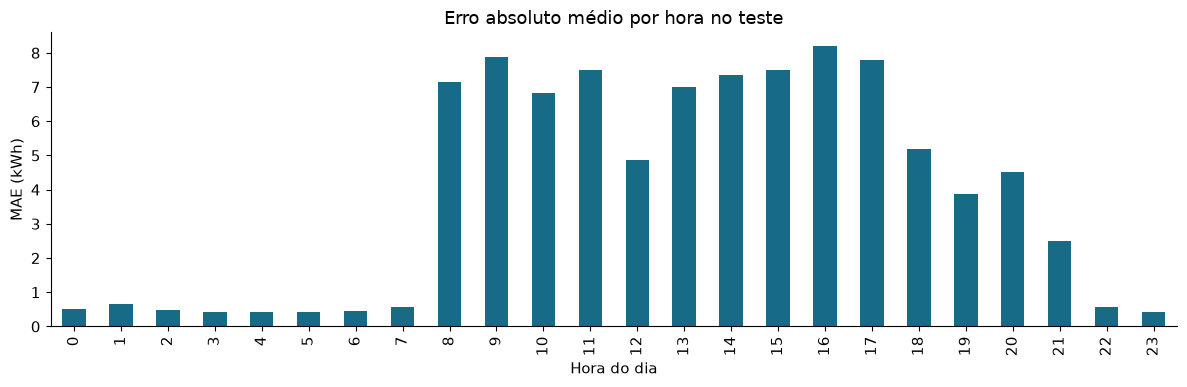

In [10]:
limiar_pico = treino['alvo_kwh'].quantile(0.90)
resultado['consumo_elevado'] = resultado['observado_kwh'] >= limiar_pico
diagnostico = resultado.groupby('consumo_elevado').agg(
    intervalos=('erro_kwh', 'size'), MAE_kWh=('erro_absoluto_kwh', 'mean'),
    vies_kWh=('erro_kwh', 'mean'))
diagnostico.index = diagnostico.index.map({False: 'Abaixo do limiar', True: 'Consumo elevado'})
display(diagnostico.round(4))
print(f'Limiar definido no treino: {limiar_pico:.2f} kWh/intervalo')
print(f'Viés médio em todo o teste: {resultado.erro_kwh.mean():.4f} kWh/intervalo')

fig, ax = plt.subplots()
resultado.groupby(resultado.index.hour)['erro_absoluto_kwh'].mean().plot.bar(ax=ax, color='#176b87')
ax.set(title='Erro absoluto médio por hora no teste', xlabel='Hora do dia', ylabel='MAE (kWh)')
fig.tight_layout()
fig.savefig(SAIDA / '05_erro_por_hora.png', dpi=160, bbox_inches='tight')
plt.show()

### 3.5 Discussão da eficácia e aplicação industrial

Uma aplicação possível é apresentar ao responsável pela operação o consumo previsto do próximo intervalo e sinalizar que uma inspeção do planejamento pode ser útil. A arquitetura proposta é: medidor → registro temporal → atributos históricos → modelo → painel de apoio à decisão. A integração com medidores, o painel e o controle de equipamentos são propostas de uso e não componentes implementados neste trabalho.

O desempenho deve ser comparado com as referências simples. Caso o modelo aprendido não as supere, não se justifica sua adoção apenas por utilizar aprendizado de máquina. O MAE descreve o tamanho típico do erro nesta amostra; não é margem garantida para cada previsão.

**Limitações:**
- Os dados pertencem a uma única indústria e a um período histórico; sua transferência para outra planta exige validação.
- Não há informações de produção por equipamento, paradas planejadas ou calendário de feriados locais neste modelo.
- Há somente um bloco temporal de validação e um de teste; não foram calculados intervalos de confiança ou comprovada superioridade estatística.
- Mudanças bruscas de regime podem reduzir a qualidade das previsões, inclusive de um modelo com bom erro médio.
- A previsão usa observações atualizadas a cada 15 minutos; não representa previsão antecipada de um dia inteiro.
- O consumo em kWh por intervalo não equivale diretamente ao valor de demanda contratada em kW. A convenção exata de início/fim do intervalo deve ser confirmada antes de integração operacional.
- Não foram estimadas economia financeira, redução de emissões ou redução efetiva do consumo: isso exigiria tarifa, intervenção e comparação de operação antes/depois.

**Próximos passos:** avaliar vários períodos com validação temporal progressiva, incorporar programação de produção conhecida antecipadamente, monitorar erro e mudança de distribuição e testar o apoio à decisão em piloto. Essas etapas não alteram retroativamente a escolha realizada neste experimento.

## 4. Conclusão baseada nos resultados executados

O texto abaixo é gerado a partir das métricas calculadas nesta execução. Assim, os números e o método citado permanecem coerentes quando o notebook é reproduzido.

In [11]:
mae_final = float(metricas_teste.loc[vencedor, 'MAE_kWh'])
mae_persistencia = float(metricas_teste.loc['Persistência', 'MAE_kWh'])
variacao = 100 * (mae_persistencia - mae_final) / mae_persistencia
comparacao = (f'redução de {variacao:.2f}% do MAE frente à persistência'
              if variacao >= 0 else f'aumento de {abs(variacao):.2f}% do MAE frente à persistência')
conclusao = f'''# Síntese dos resultados

O método selecionado pela validação foi **{vencedor}**. No teste temporal com
{len(teste):,} intervalos, entre {teste.index.min():%d/%m/%Y %H:%M} e
{teste.index.max():%d/%m/%Y %H:%M}, obteve **MAE de {mae_final:.4f} kWh por intervalo**,
**RMSE de {metricas_teste.loc[vencedor, 'RMSE_kWh']:.4f} kWh** e
**R² de {metricas_teste.loc[vencedor, 'R2']:.4f}**. O resultado representa {comparacao}.

Nos {int(resultado['consumo_elevado'].sum())} intervalos de consumo elevado,
o MAE foi **{resultado.loc[resultado['consumo_elevado'], 'erro_absoluto_kwh'].mean():.4f} kWh**,
com viés de **{resultado.loc[resultado['consumo_elevado'], 'erro_kwh'].mean():.4f} kWh**.
Nos demais intervalos, o MAE foi
**{resultado.loc[~resultado['consumo_elevado'], 'erro_absoluto_kwh'].mean():.4f} kWh**.
O viés positivo nos maiores consumos indica tendência de subestimação nesse grupo.
Por isso, a boa média geral não garante antecipação confiável dos picos.

O estudo demonstra uma aplicação reproduzível de ciência de dados ao monitoramento
energético industrial, com dados públicos, preparação temporal e avaliação posterior
ao treinamento. Os resultados são restritos à previsão sequencial de um intervalo
de 15 minutos nesta base. A eficácia em outra fábrica e eventual economia exigem
validação operacional e avaliação da intervenção.

O modelo pode apoiar o planejamento, mas não prova redução de gastos, consumo ou
emissões. Sua adoção deve considerar os erros de pico, a atualização das medições
e a comparação continuada com referências simples.
'''
display(Markdown(conclusao))
(SAIDA / 'CONCLUSAO.md').write_text(conclusao, encoding='utf-8')

# Síntese dos resultados

O método selecionado pela validação foi **HistGradientBoosting**. No teste temporal com
5,156 intervalos, entre 08/11/2018 07:15 e
01/01/2019 00:00, obteve **MAE de 3.8957 kWh por intervalo**,
**RMSE de 7.9050 kWh** e
**R² de 0.9361**. O resultado representa redução de 22.01% do MAE frente à persistência.

Nos 302 intervalos de consumo elevado,
o MAE foi **17.2832 kWh**,
com viés de **14.5872 kWh**.
Nos demais intervalos, o MAE foi
**3.0628 kWh**.
O viés positivo nos maiores consumos indica tendência de subestimação nesse grupo.
Por isso, a boa média geral não garante antecipação confiável dos picos.

O estudo demonstra uma aplicação reproduzível de ciência de dados ao monitoramento
energético industrial, com dados públicos, preparação temporal e avaliação posterior
ao treinamento. Os resultados são restritos à previsão sequencial de um intervalo
de 15 minutos nesta base. A eficácia em outra fábrica e eventual economia exigem
validação operacional e avaliação da intervenção.

O modelo pode apoiar o planejamento, mas não prova redução de gastos, consumo ou
emissões. Sua adoção deve considerar os erros de pico, a atualização das medições
e a comparação continuada com referências simples.


1231

## 5. Reprodução e arquivos produzidos

A última célula exporta previsões, métricas, auditoria, períodos dos conjuntos, metadados do modelo e ambiente utilizado. Os gráficos também são salvos em PNG. O modelo serializado contém o ajuste em treino + validação; não foi reajustado com o teste. Para uma nova previsão, é necessário construir os mesmos atributos e preservar sua ordem.

No exemplo, aplicamos o modelo aos atributos do primeiro intervalo de teste, como demonstração de inferência sobre histórico já disponível. A tabela também informa o valor observado para conferência, mas ele não é passado ao método `predict`.

In [12]:
metricas_validacao.to_csv(SAIDA / 'metricas_validacao.csv', encoding='utf-8-sig')
metricas_teste.to_csv(SAIDA / 'metricas_teste.csv', encoding='utf-8-sig')
resultado.to_csv(SAIDA / 'previsoes_teste.csv', encoding='utf-8-sig')
diagnostico.to_csv(SAIDA / 'diagnostico_picos.csv', encoding='utf-8-sig')
particoes.to_csv(SAIDA / 'particoes_temporais.csv', index=False, encoding='utf-8-sig')
metadados = {
    'fonte': URL, 'doi': '10.24432/C52G8C', 'licenca_dados': 'CC BY 4.0',
    'auditoria': auditoria, 'versoes': versoes, 'semente': SEED,
    'horizonte_minutos': 15, 'modo': 'sequencial_um_passo',
    'vencedor_validacao': vencedor, 'atributos': FEATURES,
    'limiar_consumo_elevado_kwh': float(limiar_pico),
    'MAE_teste_kwh': mae_final, 'variacao_MAE_vs_persistencia_pct': variacao,
    'linhas_modelagem': len(base), 'linhas_teste': len(teste)
}
(SAIDA / 'metadados.json').write_text(
    json.dumps(metadados, ensure_ascii=False, indent=2), encoding='utf-8')
joblib.dump({'modelo': modelo_final, 'metodo': vencedor, 'atributos': FEATURES,
             'limiar_inferior': 0, 'metadados': metadados}, SAIDA / 'modelo.joblib')

exemplo = teste.iloc[[0]]
if modelo_final is not None:
    predicao_exemplo = np.maximum(0, modelo_final.predict(exemplo[FEATURES]))[0]
else:
    predicao_exemplo = exemplo['lag_1' if vencedor == 'Persistência' else 'lag_96'].iloc[0]
display(pd.DataFrame({'instante_previsto': exemplo.index,
                      'previsto_kwh': [predicao_exemplo],
                      'observado_apenas_para_conferencia': exemplo['alvo_kwh'].values}))
print('Exportações concluídas em:', SAIDA.name)
print(*[p.name for p in sorted(SAIDA.iterdir()) if p.is_file()], sep=chr(10))

,instante_previsto,previsto_kwh,observado_apenas_para_conferencia
0,2018-11-08 07:15:00,2.999834,2.95


Exportações concluídas em: resultados
01_serie_distribuicao.png
02_perfis_calendario.png
03_observado_previsto.png
04_diagnostico_erros.png
05_erro_por_hora.png
CONCLUSAO.md
diagnostico_picos.csv
metadados.json
metricas_teste.csv
metricas_validacao.csv
modelo.joblib
particoes_temporais.csv
previsoes_teste.csv


## 6. Referências

[1] NATIONAL INSTITUTE OF STANDARDS AND TECHNOLOGY (NIST). *Data Analytics for Smart Manufacturing Systems*. Disponível em: https://www.nist.gov/programs-projects/data-analytics-smart-manufacturing-systems. Acesso em: 27 out. 2026.

[2] SATHISHKUMAR V E; SHIN, Changsun; CHO, Yongyun. *Steel Industry Energy Consumption*. UCI Machine Learning Repository, 2021. DOI: https://doi.org/10.24432/C52G8C. Dados e licença: https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption. Acesso em: 27 out. 2026.

[3] PEDREGOSA, Fabian et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011. Disponível em: https://jmlr.org/papers/v12/pedregosa11a.html.

[4] SCIKIT-LEARN DEVELOPERS. *Common pitfalls and recommended practices: data leakage*. Disponível em: https://scikit-learn.org/stable/common_pitfalls.html#data-leakage. Acesso em: 27 out. 2026.

[5] SCIKIT-LEARN DEVELOPERS. *Model evaluation: regression metrics*. Disponível em: https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics. Acesso em: 27 out. 2026.

[6] SCIKIT-LEARN DEVELOPERS. *HistGradientBoostingRegressor*. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html. Acesso em: 27 out. 2026.

**Atribuição dos dados:** os dados originais são dos autores indicados em [2] e foram redistribuídos sem alteração no CSV bruto. As defasagens, divisões, previsões e análises são transformações produzidas neste estudo. Licença dos dados: https://creativecommons.org/licenses/by/4.0/.

## 7. Conferência com o enunciado e entrega

| Requisito | Local neste notebook |
|---|---|
| Indústria 4.0, problema e objetivos | Seção 1 |
| Fonte, tipos, volume, coleta e preparação | Seções 2.1 a 2.4 e auditoria executada |
| Modelagem dos dados e métodos de análise | Seções 2.3 a 2.5 |
| Implementação em Python | Células executáveis das seções 2 a 5 |
| Resultados e discussão da eficácia | Seções 3 e 4 |
| Referências bibliográficas | Seção 6 |
| Documentação | Texto deste notebook e README do projeto |
| Link público de Colab ou GitHub | Links públicos abaixo |

**Antes da entrega:** conferir a identificação dos integrantes, revisar o texto e os resultados e executar todas as células. No Colab, clicar em **Compartilhar**, conceder acesso de visualização a qualquer pessoa com o link e testar o link em janela anônima. Alternativamente, publicar o notebook em um repositório público no GitHub e entregar a URL do arquivo. Um arquivo local não constitui o link público solicitado no enunciado.

**Links do projeto:**
- [Notebook público no GitHub](https://github.com/CodePenguinsCorp/n2-previsao-energia-industrial/blob/main/N2_Previsao_Energia_Industrial.ipynb)
- [Abrir e executar no Google Colab](https://colab.research.google.com/github/CodePenguinsCorp/n2-previsao-energia-industrial/blob/main/N2_Previsao_Energia_Industrial.ipynb)

O GitHub exibe o notebook com as saídas salvas; o Colab permite executar uma cópia.
